1. JOSE: Data Ingestion & Cleaning: Load your dataset into a Pandas DataFrame. Identify and handle missing values, correct data types, and document your choices.

In [1]:
# Import pandas
import pandas as pd
# Import numpy
import numpy as np
# Import seaborn and matplotlib 
import seaborn as sns
import matplotlib.pyplot as plt

# Set the default style for our graphs
sns.set_theme(style="whitegrid")

# Load the CSV file into a DataFrame called df
df = pd.read_csv("engineering_trends.csv", low_memory=False)

# Display the number of rows and columns
print("Dataset shape:", df.shape)

# Show the first five rows to understand the dataset
display(df.head())

Dataset shape: (30903, 212)


,ResponseId,Age,CodeMain,Education,Employment,EmploymentAddl,ICorPM,WorkSetting,LearnCode,LearnCodeHow,...,KnowledgeSourceAI,KnowAgentDelegate,KnowledgeA,TrustReason,KnowAgentTrust,ContextSelect,ContextProblems,ContextFreq,ContextWork,ConvertedCompYearly
0,1,35-44 years old,I create code as a primary part of my job,"Master's degree (M.A., M.S., M.Eng., MBA, etc.)","Independent contractor, freelancer, or self-em...",None of the above,Individual contributor in a senior or staff-le...,"Hybrid (some remote, leans heavy to in-person)",Yes,AI codegen tools or AI-enabled apps,...,Important,"Planning, scoping, or estimating work",NaN,I know who created or owns it,The AI tool chooses the information automatically,Current status or ownership,I do not know where to look,Rarely,Manually select files or documents for AI tools,NaN
1,2,45-54 years old,I create code as a primary part of my job,"Master's degree (M.A., M.S., M.Eng., MBA, etc.)",Employed,"Caring for dependents (children, elderly, etc.)",Individual contributor,Remote,No,NaN,...,Very important,"Investigating an incident, outage, or producti...",NaN,It comes from an official or trusted source;It...,I do not use AI tools or agents for work,"Code, repositories, or technical documentation...",Different teams have different versions of the...,Often,NaN,NaN
2,3,65 years or older,I create code as a primary part of my job,"Master's degree (M.A., M.S., M.Eng., MBA, etc.)",Retired,Volunteering (regularly),NaN,NaN,No,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,10000.0
3,4,Under 18 years old,I create code as a primary part of my job,Primary/elementary school,Student,Attending school (full-time);Volunteering (reg...,NaN,NaN,Yes,AI codegen tools or AI-enabled apps;Colleague ...,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,5,45-54 years old,I create code as a primary part of my job,"Bachelor's degree (B.A., B.S., B.Eng., etc.)",Employed,None of the above,Individual contributor in a senior or staff-le...,Remote,No,NaN,...,Very important,"Reviewing code, pull requests, or technical ch...",4.0,I know who created or owns it;It includes sour...,I decide exactly what information to give the ...,"Code, repositories, or technical documentation...",Information is incomplete;Information is outda...,Often,Keep notes or prompts in a separate document,85296.0


In [2]:
# Check data type
# Show the data type of every column
print("Data types:")
display(df.dtypes)

# Count how many columns belong to each data type
print("Number of columns by data type:")
display(df.dtypes.value_counts())

# Get basic information about the dataset
df.info()

Data types:


ResponseId               int64
Age                        str
CodeMain                   str
Education                  str
Employment                 str
                        ...   
ContextSelect              str
ContextProblems            str
ContextFreq                str
ContextWork                str
ConvertedCompYearly    float64
Length: 212, dtype: object

Number of columns by data type:


str        197
float64     14
int64        1
Name: count, dtype: int64

<class 'pandas.DataFrame'>
RangeIndex: 30903 entries, 0 to 30902
Columns: 212 entries, ResponseId to ConvertedCompYearly
dtypes: float64(14), int64(1), str(197)
memory usage: 50.0 MB


In [3]:
# Missing Values
# Count missing values in each column
missing_values = df.isnull().sum()

# Calculate the percentage of missing values
missing_percent = (df.isnull().mean() * 100).round(2)

# Create a table showing missing values and percentages
missing_summary = pd.DataFrame({
    "Missing Values": missing_values,
    "Missing Percentage": missing_percent
})

# Show the 20 columns with the most missing values
display(
    missing_summary.sort_values(
        by="Missing Percentage",
        ascending=False
    ).head(20)
)

# Count columns with more than 50% missing data
print("Columns with more than 50% missing values:",
      (missing_percent > 50).sum())

,Missing Values,Missing Percentage
JobDifficultyAI_9,30903,100.00
JobEaseAI_7,30903,100.00
JobEaseAI_10,30903,100.00
JobEaseAI_9,30903,100.00
JobDifficultyAI_8,30903,100.00
JobDifficultyAI_10,30903,100.00
KnowledgeSource_14,30814,99.71
KnowledgeTime_14,30810,99.70
KnowledgeAcc_14,30805,99.68
AIMemAdmired,30778,99.60


Columns with more than 50% missing values: 179


In [4]:
# Look for duplicates
# Count rows that are exactly identical
print("Duplicate rows:", df.duplicated().sum())

# Check whether the same ResponseId appears more than once
print("Duplicate Response IDs:",
      df["ResponseId"].duplicated().sum())

Duplicate rows: 0
Duplicate Response IDs: 0


In [5]:
# Clean up the dataset
# Create a copy so we do not change the original dataset
clean = df.copy()

# Remove duplicate respondents based on ResponseId
clean = clean.drop_duplicates(subset="ResponseId")

# Identify numerical columns that we want to analyze
numeric_cols = [
    "YearsCode",
    "WorkExp",
    "JobSat",
    "ToolCount",
    "AIToolCount",
    "ConvertedCompYearly"
]

# Convert these columns into numerical values
# Invalid values become NaN (missing values)
for col in numeric_cols:
    clean[col] = pd.to_numeric(clean[col], errors="coerce")

# Replace negative experience or compensation with missing values
# These values would not make sense for our analysis
for col in ["YearsCode", "WorkExp", "ConvertedCompYearly"]:
    clean.loc[clean[col] < 0, col] = np.nan

# Check the dataset after cleaning
print("Original dataset:", df.shape)
print("Cleaned dataset:", clean.shape)

# Show missing values in the variables we will analyze
display(clean[numeric_cols].isnull().sum())

Original dataset: (30903, 212)
Cleaned dataset: (30903, 212)


YearsCode               5699
WorkExp                 6296
JobSat                 12027
ToolCount              16067
AIToolCount            18984
ConvertedCompYearly    17396
dtype: int64

Part 1 Findings:
We started by loading the dataset into Pandas and checking its structure. The dataset has 30,903 observations and 212 variables. We checked for missing values, duplicates, and incorrect data types. We decided to keep missing values instead of replacing them with zero because some respondents may not have answered every question. We also converted the numerical variables into the correct format and created a cleaned version of the dataset for our analysis.

2. ALIF: Summary Statistics: Generate descriptive statistics (means, medians, standard deviations, categorical counts) to establish a baseline understanding of the variables.

In [6]:
# Alif: Summary statistics for numerical variables
summary_columns = [
    "YearsCode", "WorkExp", "JobSat",
    "ToolCount", "AIToolCount", "ConvertedCompYearly"
]

summary_values = clean[summary_columns]

# Missing answers are excluded from each variable's calculations.
numeric_summary = pd.DataFrame({
    "Available": summary_values.count(),
    "Missing": summary_values.isna().sum(),
    "Missing (%)": summary_values.isna().mean() * 100,
    "Mean": summary_values.mean(),
    "Median": summary_values.median(),
    "Std. dev.": summary_values.std(ddof=1),
    "Minimum": summary_values.min(),
    "Maximum": summary_values.max()
})

numeric_summary.index.name = "Variable"

# Show two decimal places without changing the underlying values.
with pd.option_context(
    "display.float_format", "{:,.2f}".format,
    "display.max_columns", None
):
    display(numeric_summary)

,Available,Missing,Missing (%),Mean,Median,Std. dev.,Minimum,Maximum
Variable,,,,,,,,
YearsCode,25204,5699,18.44,17.33,15.00,12.03,1.00,100.00
WorkExp,24607,6296,20.37,14.26,12.00,11.73,1.00,100.00
JobSat,18876,12027,38.92,6.96,7.00,2.15,0.00,10.00
ToolCount,14836,16067,51.99,34.87,6.00,478.94,0.00,"10,000.00"
AIToolCount,11919,18984,61.43,"92,307,864,391.81",2.00,"9,205,283,519,134.44",0.00,"999,999,999,999,999.00"
ConvertedCompYearly,13507,17396,56.29,"106,535.07","79,610.00","445,367.66",1.00,"31,919,350.00"


In [7]:
# Alif: Summary statistics for categorical variables
category_columns = [
    "Education", "Employment", "WorkSetting", "Country", "Role"
]
category_values = clean[category_columns]

# Show how many respondents answered each question.
category_coverage = pd.DataFrame({
    "Answered": category_values.notna().sum(),
    "Missing": category_values.isna().sum(),
    "Missing (%)": (category_values.isna().mean() * 100).round(2),
    "Distinct reported categories": category_values.nunique()
})
category_coverage.index.name = "Variable"
display(category_coverage)

category_tables = {}

for column in category_columns:
    # Include missing answers as a separate row.
    counts = clean[column].value_counts()
    counts.loc["Missing / not answered"] = clean[column].isna().sum()

    table = pd.DataFrame({
        "Count": counts,
        "Percent of all respondents (%)": (
            counts / len(clean) * 100
        ).round(2)
    })
    table.index.name = column
    category_tables[column] = table

    # Show the top 10 countries and roles, combining the rest.
    if column in ["Country", "Role"]:
        reported_counts = counts.drop("Missing / not answered")
        shown_counts = reported_counts.head(10).copy()
        shown_counts.loc["All remaining reported categories (combined)"] = (
            reported_counts.iloc[10:].sum()
        )
        shown_counts.loc["Missing / not answered"] = (
            counts.loc["Missing / not answered"]
        )

        table = pd.DataFrame({
            "Count": shown_counts,
            "Percent of all respondents (%)": (
                shown_counts / len(clean) * 100
            ).round(2)
        })
        table.index.name = column

    print(f"\n{column}: counts and percentages of all respondents")
    with pd.option_context(
        "display.max_colwidth", None,
        "display.max_rows", None
    ):
        display(table)

,Answered,Missing,Missing (%),Distinct reported categories
Variable,,,,
Education,30761,142,0.46,8
Employment,30903,0,0.00,6
WorkSetting,24602,6301,20.39,5
Country,21370,9533,30.85,169
Role,25767,5136,16.62,41



Education: counts and percentages of all respondents


,Count,Percent of all respondents (%)
Education,,
"Bachelor's degree (B.A., B.S., B.Eng., etc.)",12396,40.11
"Master's degree (M.A., M.S., M.Eng., MBA, etc.)",7990,25.86
Some college/university study without earning a degree,3813,12.34
"Secondary school (e.g. American high school, German Realschule or Gymnasium, etc.)",2431,7.87
"Professional degree (JD, MD, Ph.D, Ed.D, etc.)",1812,5.86
"Associate degree (A.A., A.S., etc.)",942,3.05
Primary/elementary school,706,2.28
"Other, please specify",671,2.17
Missing / not answered,142,0.46



Employment: counts and percentages of all respondents


,Count,Percent of all respondents (%)
Employment,,
Employed,20259,65.56
"Independent contractor, freelancer, or self-employed",4607,14.91
Student,3139,10.16
Not employed,1742,5.64
Retired,607,1.96
I prefer not to say,549,1.78
Missing / not answered,0,0.00



WorkSetting: counts and percentages of all respondents


,Count,Percent of all respondents (%)
WorkSetting,,
Remote,8564,27.71
"Hybrid (some remote, leans heavy to in-person)",4883,15.80
In-person,4335,14.03
"Hybrid (some in-person, leans heavy to flexibility)",3823,12.37
"Your choice (very flexible, you can come in when you want or just as needed)",2997,9.70
Missing / not answered,6301,20.39



Country: counts and percentages of all respondents


,Count,Percent of all respondents (%)
Country,,
United States of America,4755,15.39
Germany,1983,6.42
United Kingdom of Great Britain and Northern Ireland,1374,4.45
India,1309,4.24
Canada,851,2.75
France,794,2.57
Netherlands,577,1.87
Poland,527,1.71
Australia,522,1.69



Role: counts and percentages of all respondents


,Count,Percent of all respondents (%)
Role,,
"Developer, full-stack",7042,22.79
"Developer, back-end",3473,11.24
Student,1823,5.90
"Architect, software or solutions",1792,5.80
"Developer, desktop or enterprise applications",1030,3.33
"Developer, front-end",933,3.02
"Developer, embedded applications or devices",731,2.37
Academic researcher,705,2.28
"Developer, mobile",685,2.22


In [8]:
# Alif: Count respondents who reported using each language.
language_answers = clean["LanguagesHaveWorkedWith"].dropna()

# "Python;SQL" contributes once to Python and once to SQL.
language_indicators = language_answers.str.get_dummies(sep=";")
language_counts = language_indicators.sum().sort_values(ascending=False)

language_summary = pd.DataFrame({
    "Respondents": language_counts,
    "Percent of language-question respondents (%)": (
        language_counts / len(language_answers) * 100
    ).round(2)
})
language_summary.index.name = "Language / technology"

print(f"Answered the language question: {len(language_answers):,}")
print(
    f"Missing language answers: "
    f"{clean['LanguagesHaveWorkedWith'].isna().sum():,}"
)
print("Percentages use respondents who answered the language question.")
print("A respondent can select multiple languages, so percentages can exceed 100% in total.")

with pd.option_context("display.max_rows", None):
    display(language_summary)

Answered the language question: 13,924
Missing language answers: 16,979
Percentages use respondents who answered the language question.
A respondent can select multiple languages, so percentages can exceed 100% in total.


,Respondents,Percent of language-question respondents (%)
Language / technology,,
JavaScript,8742,62.78
SQL,8237,59.16
HTML/CSS,8211,58.97
Python,8182,58.76
Bash/Shell (all shells),7231,51.93
TypeScript,6169,44.30
Java,3884,27.89
C#,3818,27.42
PowerShell,3472,24.94


### Part 2 findings: Summary statistics

**Approach:** I used the cleaned dataset from Part 1, containing 30,903 respondents. This includes students and retired respondents as well as people currently working. Numerical calculations exclude missing answers separately for each variable, and standard deviations use the sample formula (`ddof=1`). Missing values remain missing rather than being replaced with zero. Compensation uses `ConvertedCompYearly`, following Part 3's USD convention.

**Numerical results:**

- Years of coding have a mean of 17.33 and a median of 15. Professional work experience has a mean of 14.26 years, a median of 12 years, and a standard deviation of 11.73 years.
- Converted annual compensation has a mean of 106,535.07 USD, a median of 79,610 USD, and a standard deviation of 445,367.66 USD. These statistics use 13,507 available responses. Compensation is missing for 17,396 respondents (56.29%), so the results describe only those with available compensation.
- The maximum compensation is 31,919,350 USD. Very large values affect the mean and standard deviation; the median is less sensitive to these extreme values.
- Job satisfaction has a mean of 6.96 and a median of 7. The median tool count is 6, and the median AI-tool count is 2.
- Some values need further checking: both experience variables reach 100 years, tool count reaches 10,000, and AI-tool count reaches 999,999,999,999,999. I retained these values in the baseline summary and flagged them rather than choosing an unsupported cutoff. In particular, the AI-tool mean should not be interpreted as typical tool use.

**Categorical results:**

The percentages in these tables use all 30,903 respondents, including missing answers. A bachelor's degree is the most frequently reported education level (12,396 respondents; 40.11%). The "Employed" category contains 20,259 respondents (65.56%). Remote is the most frequently reported work setting (8,564 respondents; 27.71%). Country and role displays show the top ten categories, the remaining categories combined, and missing answers; complete tables are stored in `category_tables`.

**Language results:**

The language question has 13,924 responses and 16,979 missing answers (54.94%). JavaScript is the most frequently selected option (8,742 respondents; 62.78% of those who answered). Python was selected by 8,182 respondents (58.76%). Each language is counted at most once per respondent. Since respondents can select several languages, the percentages can total more than 100%.

These summaries describe the survey respondents and provide a starting point for later analysis. They do not establish that learning a particular language causes higher pay. Later salary comparisons should consider experience, country, employment status, missing answers, and questionable extreme values.

**Contribution — Alif:** Numerical summary statistics, categorical and language counts, missing-response summaries, and interpretation of the results.

3. JOSE: Initial Visualizations: Create foundational plots (e.g., histograms, scatter plots, box plots using Seaborn) to identify distributions, outliers, and potential correlations.

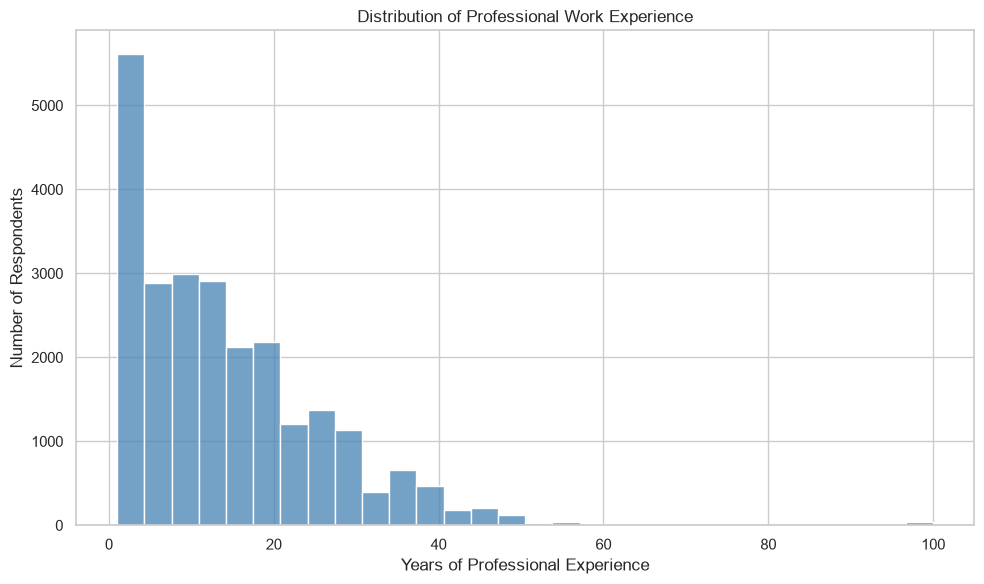

In [9]:
# Create the figure and set its size
plt.figure(figsize=(10, 6))

# Create a histogram showing years of professional experience
sns.histplot(
    data=clean,
    x="WorkExp",
    bins=30,              # Divide experience into 30 intervals
    color="steelblue",    # Set the bar color
    edgecolor="white"     # Add white borders between bars
)

# Add a descriptive title
plt.title("Distribution of Professional Work Experience")

# Label the horizontal axis
plt.xlabel("Years of Professional Experience")

# Label the vertical axis
plt.ylabel("Number of Respondents")

# Adjust spacing so labels are not cut off
plt.tight_layout()

# Display the graph
plt.show()

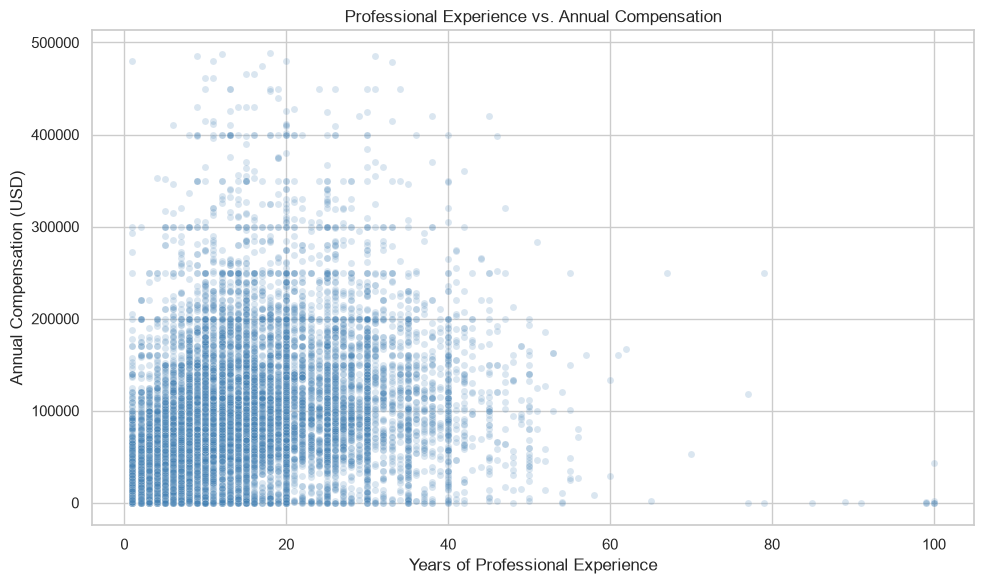

In [10]:
# Keep respondents who reported both experience and compensation
salary_data = clean.dropna(
    subset=["WorkExp", "ConvertedCompYearly"]
).copy()

# Keep only positive compensation values
salary_data = salary_data[
    salary_data["ConvertedCompYearly"] > 0
]

# Find the 99th percentile of compensation
# This helps limit the influence of extremely high salaries on the graph
salary_limit = salary_data["ConvertedCompYearly"].quantile(0.99)

# Create a dataset for plotting without the top 1% of salaries
salary_plot = salary_data[
    salary_data["ConvertedCompYearly"] <= salary_limit
].copy()

# Set the graph size
plt.figure(figsize=(10, 6))

# Create a scatter plot comparing experience and compensation
sns.scatterplot(
    data=salary_plot,
    x="WorkExp",
    y="ConvertedCompYearly",
    alpha=0.2,           # Make points transparent to see overlapping values
    color="steelblue",
    s=25                 # Set the size of each point
)

# Add a title and axis labels
plt.title("Professional Experience vs. Annual Compensation")
plt.xlabel("Years of Professional Experience")
plt.ylabel("Annual Compensation (USD)")

# Adjust spacing and display the graph
plt.tight_layout()
plt.show()

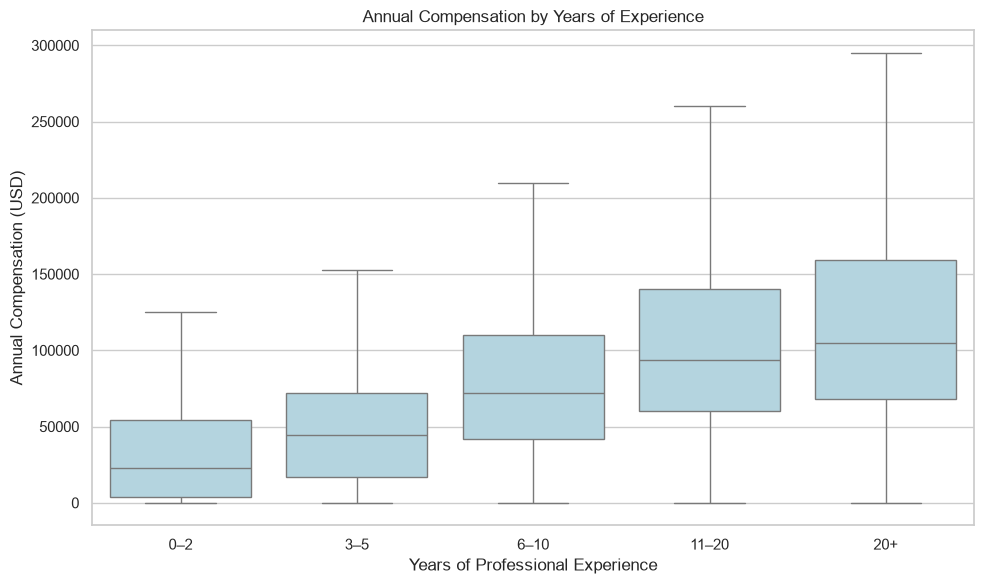

In [11]:
# Create a copy of the salary dataset for this graph
experience_data = salary_plot.copy()

# Divide respondents into five experience groups
experience_data["Experience Group"] = pd.cut(
    experience_data["WorkExp"],
    bins=[-0.01, 2, 5, 10, 20, np.inf],
    labels=["0–2", "3–5", "6–10", "11–20", "20+"]
)

# Set the graph size
plt.figure(figsize=(10, 6))

# Create a box plot comparing compensation across experience groups
sns.boxplot(
    data=experience_data,
    x="Experience Group",
    y="ConvertedCompYearly",
    color="lightblue",
    showfliers=False     # Hide outlier dots to make the graph easier to read
)

# Add the title and axis labels
plt.title("Annual Compensation by Years of Experience")
plt.xlabel("Years of Professional Experience")
plt.ylabel("Annual Compensation (USD)")

# Adjust spacing and display the graph
plt.tight_layout()
plt.show()

4. SEDAN: Dataset Quirks: Document initial observations, inherent biases in the data collection, and any assumptions you will need to make moving forward.

Part 4 findings: Dataset quirks, biases, and assumptions
Quirks

Over half of salary data is missing. Only 13,507 of 30,903 respondents (43.7%) reported a salary, and response rates differ by group (53% of employed respondents vs. 12% of students).
Salary has implausible values. 521 answers are 1,000 or less and 26 are above 1,000,000 (maximum about $31.9 million), so medians are more reliable than means.
Pay is converted to USD from many currencies with no cost-of-living adjustment, and it varies hugely by country (median about 
17,000 in India).
Experience and tool counts contain impossible values (up to 100 years of experience, 10,000 tools).
The sample includes students, retirees, under-18s, and occasional coders. 179 of 212 columns are more than half empty, and languages are stored as semicolon-separated text

Biases

It is a voluntary online survey, not a random sample of developers. The US makes up 15.4% of respondents, and 86% of those who gave a gender are men.
Salaries are self-reported and unverified, and people who skipped the question may earn differently from those who answered.
Each person answered once, so the data can show association but cannot show that learning a language raises pay.

Assumptions going forward

We will focus on working developers (employed or self-employed, coding as a primary part of the job): 20,220 respondents, 10,561 with a salary.
We will use ConvertedCompYearly with a documented outlier rule, and use medians or log pay.
We will compare pay within a country or control for country, not mix countries.
We will not fill in missing values, and we will report sample sizes.
We will describe results as associations, not cause and effect.

JOSE
Deliverable 2: Analysis and Pitch
Investigation 1: The Remote Work Divide and Salary Spread
Part A: Mean, median, and variance by work setting

In [12]:
# Use the cleaned data from Deliverable 1 without changing it.
work = clean.copy()

# The survey has two hybrid categories. Combine them into one group.
# "Your choice" and missing work settings are not forced into a group.
work["WorkGroup"] = np.select(
    [work["WorkSetting"].eq("Remote"),
     work["WorkSetting"].eq("In-person"),
     work["WorkSetting"].fillna("").str.startswith("Hybrid")],
    ["Remote", "In-Person", "Hybrid"],
    default="Other/Unknown"
)

# Keep the requested groups and respondents with a positive annual salary.
work = work[
    work["WorkGroup"].isin(["Remote", "In-Person", "Hybrid"])
    & work["ConvertedCompYearly"].gt(0)
].copy()

# The variance is the sample variance (ddof=1, Pandas default).
salary_summary = work.groupby("WorkGroup")["ConvertedCompYearly"].agg(
    respondents="count", mean="mean", median="median", variance="var"
)
display(salary_summary.round(2))

,respondents,mean,median,variance
WorkGroup,,,,
Hybrid,4806,103950.39,80705.5,1.980882e+11
In-Person,1817,93418.62,53206.0,2.510710e+11
Remote,4606,114563.07,93098.0,2.525166e+10


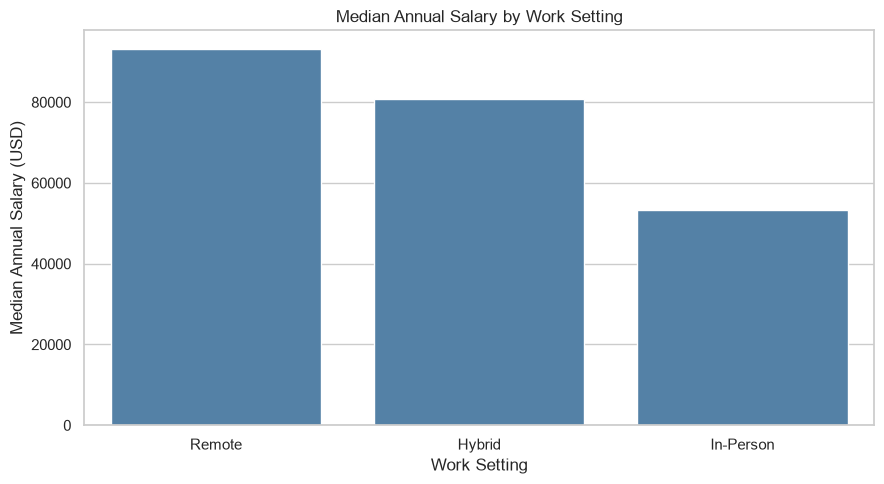

In [13]:
# Compare median salaries, which are less affected by very high salaries.
order = ["Remote", "Hybrid", "In-Person"]
plt.figure(figsize=(9, 5))
sns.barplot(data=work, x="WorkGroup", y="ConvertedCompYearly",
            estimator=np.median, errorbar=None, order=order, color="steelblue")
plt.title("Median Annual Salary by Work Setting")
plt.xlabel("Work Setting")
plt.ylabel("Median Annual Salary (USD)")
plt.tight_layout()
plt.show()

Part A findings: Based on our results, remote workers had the highest average salary at $114,563, compared to $103,950 for hybrid and $93,419 for in-person workers. This means remote workers earned about $21,144 more on average than in-person workers. However, I would not recommend that a graduating senior only apply for remote jobs based on these numbers. The median salary for remote workers was $93,098, which is $21,465 lower than their average. This shows how higher salaries can increase the average and give someone unrealistic expectations. Also, in-person workers had a much higher variance of $251 billion compared to $25 billion for remote workers, meaning their salaries were much more spread out. I think it would be better to consider all three work settings instead of limiting job opportunities based only on average salaries.

JOSE
Part B: Covariance and correlation between experience and salary

In [14]:
# Use the full cleaned dataset, not just the three work-setting groups.
experience_salary = clean[["WorkExp", "ConvertedCompYearly"]].dropna().copy()
experience_salary = experience_salary[experience_salary["ConvertedCompYearly"] > 0]

# Covariance shows whether the variables tend to move together.
covariance = experience_salary["WorkExp"].cov(experience_salary["ConvertedCompYearly"])

# Pearson correlation is standardized from -1 to +1.
correlation = experience_salary["WorkExp"].corr(experience_salary["ConvertedCompYearly"])
print("Number of complete pairs:", len(experience_salary))
print(f"Covariance: {covariance:,.2f}")
print(f"Correlation: {correlation:.4f}")

Number of complete pairs: 13373
Covariance: 322,971.46
Correlation: 0.0668


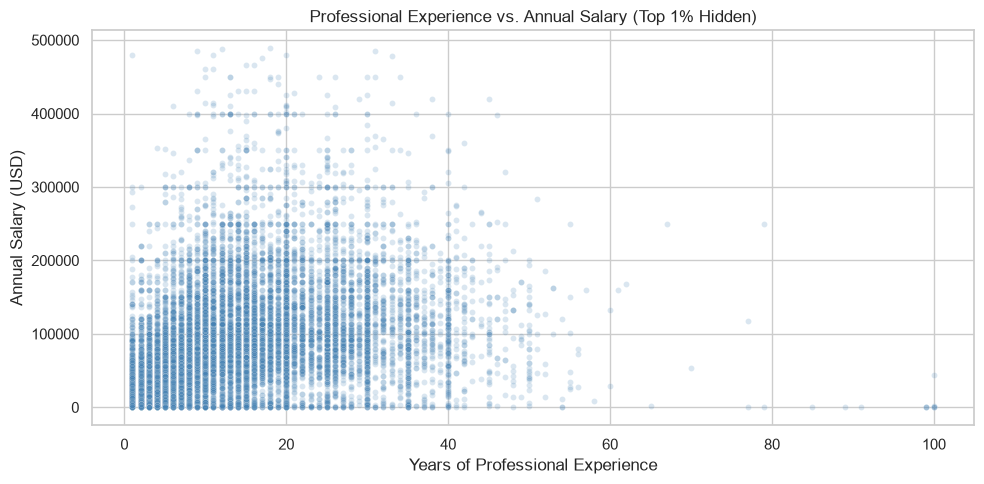

In [15]:
# Exclude the highest 1% of salaries only from the plot for readability.
# Do not exclude them from the correlation calculation above.
cap = experience_salary["ConvertedCompYearly"].quantile(0.99)
plot_experience = experience_salary[experience_salary["ConvertedCompYearly"] <= cap]
plt.figure(figsize=(10, 5))
sns.scatterplot(data=plot_experience, x="WorkExp", y="ConvertedCompYearly",
                alpha=0.2, s=18, color="steelblue")
plt.title("Professional Experience vs. Annual Salary (Top 1% Hidden)")
plt.xlabel("Years of Professional Experience")
plt.ylabel("Annual Salary (USD)")
plt.tight_layout()
plt.show()

The correlation was 0.0668, which is positive but not the strongest. I expected a stronger relationship, but years of experience alone do not explain much of the salary differences. Other factors, like country and job position, probably matter too. Correlation does not prove causation.

JOSE
Part C: Correlation Remote vs. In-Person

In [16]:
# Part C: Compare experience and salary for Remote vs. In-Person workers

# Create a table to store the results
correlation_results = []

# Calculate the correlation separately for each work setting
for group in ["Remote", "In-Person"]:

    # Select workers from the current group
    group_data = work[work["WorkGroup"] == group]

    # Keep only respondents with both experience and salary data
    group_data = group_data.dropna(
        subset=["WorkExp", "ConvertedCompYearly"]
    )

    # Calculate Pearson correlation
    correlation = group_data["WorkExp"].corr(
        group_data["ConvertedCompYearly"]
    )

    # Save the results
    correlation_results.append({
        "Work Setting": group,
        "Number of Workers": len(group_data),
        "Correlation": correlation
    })

# Convert the results into a DataFrame
correlation_table = pd.DataFrame(correlation_results)

# Display the table
display(correlation_table.round(4))

,Work Setting,Number of Workers,Correlation
0,Remote,4585,0.1621
1,In-Person,1792,0.0333


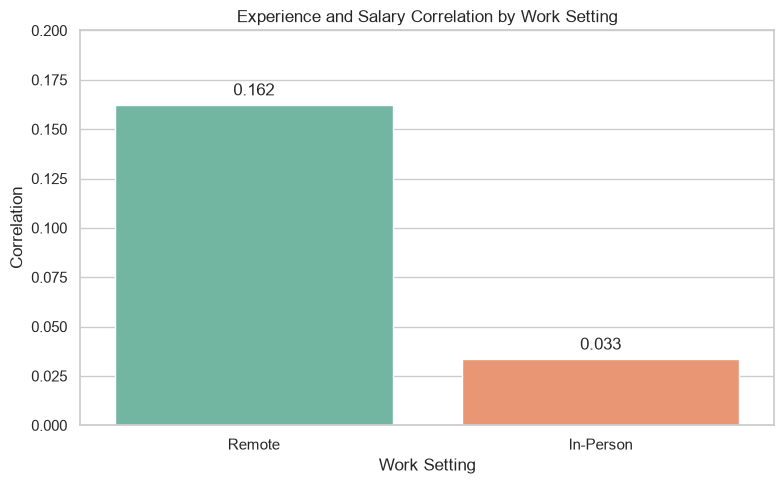

In [17]:
# Visualize the correlation for Remote and In-Person workers

plt.figure(figsize=(8, 5))

# Create a bar chart comparing both correlations
sns.barplot(
    data=correlation_table,
    x="Work Setting",
    y="Correlation",
    hue="Work Setting",
    palette="Set2",
    legend=False
)

# Add labels and title
plt.title("Experience and Salary Correlation by Work Setting")
plt.xlabel("Work Setting")
plt.ylabel("Correlation")

# Start the y-axis at zero
plt.ylim(0, 0.20)

# Show correlation values above each bar
for i, value in enumerate(correlation_table["Correlation"]):
    plt.text(i, value + 0.005, f"{value:.3f}", ha="center")

plt.tight_layout()
plt.show()

Part C Findings: When comparing remote and in-person workers, we found that remote workers had a stronger correlation between experience and salary at 0.162, compared to only 0.033 for in-person workers. This suggests that experience has a stronger relationship with higher salaries in remote jobs, while the relationship is almost nonexistent for in-person jobs. However, both correlations are weak, meaning that having more experience does not necessarily guarantee a higher salary in either work setting. Other factors like job position and country could also influence salaries.

Investigation 2: Trendy Languages

### ALIF: Question, groups, and hypotheses

Do working developers who report using Rust or Go have higher average annual compensation than those who report Python or Java without Rust or Go?

I use `clean` from Deliverable 1. Following the team's working-developer definition in Part 4, I include respondents who are employed or self-employed and create code as a primary part of their job. Compensation is `ConvertedCompYearly` in USD, following the project's existing convention. Each respondent must have a reported language answer and positive, finite compensation.

- **Rust/Go group:** reports Rust or Go, including respondents who also report Python or Java.
- **Python/Java comparison group:** reports Python or Java and reports neither Rust nor Go.

Language selections are separated by semicolons. I match complete language names, so JavaScript does not count as Java. Respondents reporting both language families belong only to the Rust/Go group. People reporting none of these four languages are excluded. The comparison is therefore between two sets of respondents, not between people using only one language.

**Null hypothesis (H0):** There is no salary association with this grouping; under the permutation model, salary values are exchangeable across the two groups, with equal expected means.

**Alternative hypothesis (H1):** The Rust/Go group has a higher mean annual compensation than the comparison group.

The statistic is **mean(Rust/Go) minus mean(Python/Java without Rust/Go)**. I use a one-sided permutation test with 10,000 shuffles, random seed 42, and a significance level of 0.05. This adapts the independent-groups example in [Lab 07](https://github.com/allegheny-college-cmpsc-105-fall-2026/cmpsc105-lab07/blob/main/lab07.ipynb). Larger positive differences support H1, so the p-value uses the upper tail.

The main test retains all eligible salaries, including extreme reports. A separate sensitivity check repeats the test after excluding values above the combined sample's 99th percentile, using the same cutoff for both groups. This follows the project's existing use of a 99th-percentile plotting cutoff and lets us check how extreme salaries affect the result.

In [18]:
# Start with working developers, as defined in the team's Part 4.
lang_working = (
    clean["Employment"].isin([
        "Employed", "Independent contractor, freelancer, or self-employed"
    ])
    & clean["CodeMain"].eq("I create code as a primary part of my job")
)
lang_population = clean.loc[lang_working].copy()

# Each language becomes a separate indicator; missing answers select none.
lang_flags = (
    lang_population["LanguagesHaveWorkedWith"].fillna("")
    .str.get_dummies(sep=";")
)
lang_rust_go = lang_flags.reindex(columns=["Rust", "Go"], fill_value=0).any(axis=1)
lang_python_java = lang_flags.reindex(columns=["Python", "Java"], fill_value=0).any(axis=1)

# Assign every included respondent to exactly one group.
lang_grouped = lang_population.loc[lang_rust_go | lang_python_java].copy()
lang_grouped["LanguageGroup"] = np.where(
    lang_rust_go.loc[lang_grouped.index],
    "Rust/Go", "Python/Java without Rust/Go"
)
lang_order = ["Rust/Go", "Python/Java without Rust/Go"]

lang_valid_salary = (
    np.isfinite(lang_grouped["ConvertedCompYearly"])
    & lang_grouped["ConvertedCompYearly"].gt(0)
)
lang_data = lang_grouped.loc[lang_valid_salary].copy()

# Show exclusions so readers can see which respondents the test describes.
lang_coverage = pd.DataFrame({
    "Selected by languages": lang_grouped.groupby("LanguageGroup").size(),
    "Usable salaries": lang_data.groupby("LanguageGroup").size()
}).reindex(lang_order).fillna(0).astype(int)
lang_coverage["Excluded salaries"] = (
    lang_coverage["Selected by languages"] - lang_coverage["Usable salaries"]
)

print(f"Working developers: {len(lang_population):,}")
print(f"Missing language answers: {lang_population['LanguagesHaveWorkedWith'].isna().sum():,}")
print(f"Reported languages but none of these four: {((lang_population['LanguagesHaveWorkedWith'].notna()) & ~(lang_rust_go | lang_python_java)).sum():,}")
print(f"Reported both language families, assigned only to Rust/Go: {(lang_rust_go & lang_python_java).sum():,}")
display(lang_coverage)

lang_summary = (
    lang_data.groupby("LanguageGroup")["ConvertedCompYearly"]
    .agg(["count", "mean", "median", "std", "min", "max"])
    .reindex(lang_order)
    .rename(columns={"count": "Respondents", "mean": "Mean (USD)",
                     "median": "Median (USD)", "std": "Sample SD (USD)",
                     "min": "Minimum (USD)", "max": "Maximum (USD)"})
)
with pd.option_context("display.float_format", "{:,.2f}".format, "display.max_columns", None):
    display(lang_summary)

Working developers: 20,220
Missing language answers: 10,550
Reported languages but none of these four: 2,629
Reported both language families, assigned only to Rust/Go: 2,123


,Selected by languages,Usable salaries,Excluded salaries
LanguageGroup,,,
Rust/Go,2750,2133,617
Python/Java without Rust/Go,4291,3307,984


,Respondents,Mean (USD),Median (USD),Sample SD (USD),Minimum (USD),Maximum (USD)
LanguageGroup,,,,,,
Rust/Go,2133,"122,043.29","90,982.00","283,630.87",1.00,"10,639,783.00"
Python/Java without Rust/Go,3307,"107,568.77","81,884.00","529,550.91",1.00,"30,000,000.00"


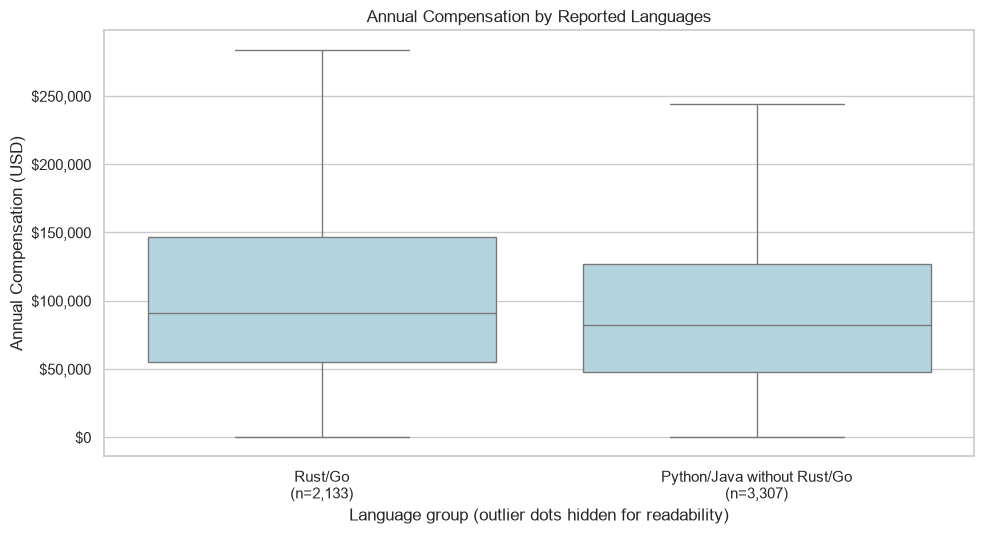

In [19]:
# Hide outlier dots only in this graph; the main test still uses all salaries.
from matplotlib.ticker import StrMethodFormatter

plt.figure(figsize=(10, 5.5))
lang_ax = sns.boxplot(
    data=lang_data, x="LanguageGroup", y="ConvertedCompYearly",
    order=lang_order, color="lightblue", showfliers=False
)
lang_ax.set_xticks([0, 1], labels=[
    f"Rust/Go\n(n={lang_summary.loc[lang_order[0], 'Respondents']:,.0f})",
    f"Python/Java without Rust/Go\n(n={lang_summary.loc[lang_order[1], 'Respondents']:,.0f})"
])
lang_ax.yaxis.set_major_formatter(StrMethodFormatter("${x:,.0f}"))
plt.title("Annual Compensation by Reported Languages")
plt.xlabel("Language group (outlier dots hidden for readability)")
plt.ylabel("Annual Compensation (USD)")
plt.tight_layout()
plt.show()

Respondents in the main test: 5,440
Observed mean difference (Rust/Go minus comparison): $14,474.51
Shuffled differences at least as large: 1,850 of 10,000
One-sided permutation p-value: 0.18508
Fail to reject H0 at 0.05.


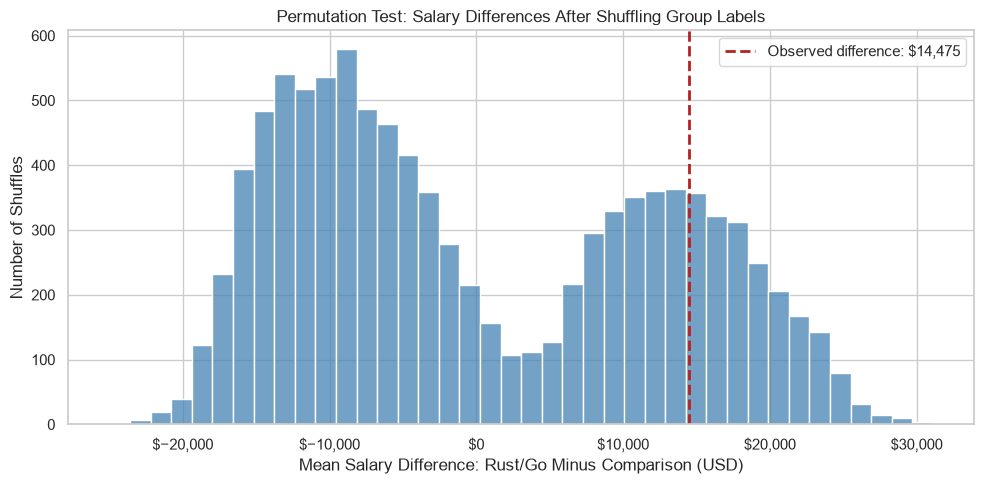

In [20]:
# Adapt Lab 07's independent-groups permutation test.
def lang_permutation_test(data, n_iter=10000, seed=42):
    salaries = data["ConvertedCompYearly"].to_numpy(dtype=float)
    labels = data["LanguageGroup"].eq("Rust/Go").to_numpy()
    if labels.sum() == 0 or (~labels).sum() == 0:
        raise ValueError("Both language groups need salary observations.")

    observed = salaries[labels].mean() - salaries[~labels].mean()
    rng = np.random.default_rng(seed)
    simulated = np.empty(n_iter)

    for i in range(n_iter):
        # Keep salaries fixed and shuffle group labels, preserving group sizes.
        shuffled = rng.permutation(labels)
        simulated[i] = salaries[shuffled].mean() - salaries[~shuffled].mean()

    # H1 predicts HIGHER Rust/Go pay, so use the upper tail (>=).
    extreme = np.count_nonzero(simulated >= observed)
    # The +1 correction prevents a simulated p-value of exactly zero.
    p_value = (extreme + 1) / (n_iter + 1)
    return observed, p_value, simulated, extreme

lang_observed, lang_p_value, lang_null, lang_extreme = lang_permutation_test(lang_data)
lang_alpha = 0.05

print(f"Respondents in the main test: {len(lang_data):,}")
print(f"Observed mean difference (Rust/Go minus comparison): ${lang_observed:,.2f}")
print(f"Shuffled differences at least as large: {lang_extreme:,} of {len(lang_null):,}")
print(f"One-sided permutation p-value: {lang_p_value:.5f}")
print("Reject H0 at 0.05." if lang_p_value < lang_alpha else "Fail to reject H0 at 0.05.")

plt.figure(figsize=(10, 5))
lang_ax = sns.histplot(lang_null, bins=40, color="steelblue", edgecolor="white")
plt.axvline(lang_observed, color="firebrick", linestyle="--", linewidth=2,
            label=f"Observed difference: ${lang_observed:,.0f}")
lang_ax.xaxis.set_major_formatter(StrMethodFormatter("${x:,.0f}"))
plt.title("Permutation Test: Salary Differences After Shuffling Group Labels")
plt.xlabel("Mean Salary Difference: Rust/Go Minus Comparison (USD)")
plt.ylabel("Number of Shuffles")
plt.legend()
plt.tight_layout()
plt.show()

### Sensitivity to extreme salaries

The main sample includes salaries as low as $1 and as high as $30 million. Their validity cannot be checked from this file alone. The following check removes the highest 1% using one pooled cutoff; it does not establish that those records are errors or replace the main test. Lower extreme values remain included.

In [21]:
# Use one salary cutoff across the combined sample, not separate group cutoffs.
lang_cutoff = lang_data["ConvertedCompYearly"].quantile(0.99)
lang_trimmed = lang_data.loc[lang_data["ConvertedCompYearly"] <= lang_cutoff].copy()
lang_trim_diff, lang_trim_p, lang_trim_null, lang_trim_extreme = lang_permutation_test(lang_trimmed)

lang_sensitivity = pd.DataFrame({
    "Analysis": ["Main: all eligible salaries", "Sensitivity: at or below pooled 99th percentile"],
    "Rust/Go respondents": [
        lang_data["LanguageGroup"].eq("Rust/Go").sum(),
        lang_trimmed["LanguageGroup"].eq("Rust/Go").sum()
    ],
    "Comparison respondents": [
        lang_data["LanguageGroup"].ne("Rust/Go").sum(),
        lang_trimmed["LanguageGroup"].ne("Rust/Go").sum()
    ],
    "Mean difference (USD)": [lang_observed, lang_trim_diff],
    "One-sided p-value": [lang_p_value, lang_trim_p]
}).set_index("Analysis")
print(f"Pooled 99th-percentile cutoff: ${lang_cutoff:,.2f}")
print(f"Respondents excluded in the sensitivity check: {len(lang_data) - len(lang_trimmed):,}")
with pd.option_context("display.max_columns", None, "display.float_format", "{:,.5f}".format):
    display(lang_sensitivity)
print(f"Sensitivity-check upper-tail count: {lang_trim_extreme:,} of {len(lang_trim_null):,}")
print("The sensitivity-check p-value is estimated from 10,000 shuffles; its smallest possible corrected value is 1/10,001.")

Pooled 99th-percentile cutoff: $495,568.82
Respondents excluded in the sensitivity check: 55


,Rust/Go respondents,Comparison respondents,Mean difference (USD),One-sided p-value
Analysis,,,,
Main: all eligible salaries,2133,3307,"14,474.51220",0.18508
Sensitivity: at or below pooled 99th percentile,2100,3285,"11,809.31779",0.00010


Sensitivity-check upper-tail count: 0 of 10,000
The sensitivity-check p-value is estimated from 10,000 shuffles; its smallest possible corrected value is 1/10,001.


### Investigation 2 findings

I compared **2,133 Rust/Go respondents** with **3,307 Python/Java respondents who did not report Rust or Go**. Both groups are working developers with positive reported annual compensation. The average was **$122,043.29** for Rust/Go and **$107,568.77** for the comparison group, a difference of **$14,474.51**. The medians were **$90,982** and **$81,884**, respectively.

The one-sided permutation test gave **p = 0.18508**. With a 0.05 significance level, I **fail to reject the null hypothesis**. The Rust/Go mean is higher in this sample, but the main test does not provide sufficient evidence of higher mean compensation under the permutation model. This does not prove that the groups have equal salaries. The p-value is the simulated upper-tail frequency under the null model, not the probability that the null hypothesis is true.

Extreme salaries affect this comparison. After excluding the **55** salaries above the pooled 99th-percentile cutoff of **$495,568.82**, the mean difference was **$11,809.32** and the corrected simulated p-value was approximately **0.00010**. None of the 10,000 shuffled differences was as large as the observed trimmed difference; the reported value is the simulation's minimum corrected p-value, not an exact zero. This check provides evidence of a difference for the trimmed sample, but it also shows that the test's conclusion depends on how extreme salary reports are handled. I report it separately from the main result.

The student's claim that learning a trendy language *automatically* produces higher pay is not supported. Respondents were not randomly assigned to learn languages, and the survey does not track their salaries before and after learning. Country, experience, job role, and other skills can differ between groups. Also, **10,550 of 20,220 working developers** did not answer the language question, and **1,601 of the 7,041 language-eligible respondents** lacked usable salary data. These results describe the respondents included in this comparison and cannot establish that learning Rust or Go causes a raise.

**Contribution — Alif:** Defined the language groups, checked salary coverage, adapted the permutation test from Lab 07, created the graphs, checked sensitivity to extreme salaries, and interpreted the results.


Original Research Question and Plan

## Proposed original questions — Alif

These are proposed questions for the final investigation, not completed findings. They extend the guided work by examining education and career roles. The team should review this scope before the final analysis.

### Shared sample and variables

Start with a copy of `clean` from Deliverable 1. Use the team's working-developer definition: `Employment` is `Employed` or `Independent contractor, freelancer, or self-employed`, and `CodeMain` is `I create code as a primary part of my job`.

For both questions, restrict `Country` to `United States of America`. This fits the department's U.S. advising context and avoids pooling pay across national labor markets. Use `ConvertedCompYearly` as reported annual compensation in USD. Require positive, finite compensation and finite, nonnegative `WorkExp`. Exclude missing or out-of-scope education/role answers separately for each question; do not replace missing values with zero. Report the number retained and excluded at each step.

### Question 1: Education during the first five career years

**Question:** Among U.S. working developers with 0–5 years of professional experience, is median annual compensation higher for respondents with a master's degree than for those with a bachelor's degree?

**Why it matters:** Students considering graduate study need evidence about reported pay early in a career. The survey cannot establish whether a degree pays for itself because it does not provide tuition costs, degree field, or before-and-after earnings.

**Groups and variables:** Require `0 <= WorkExp <= 5`. Compare these exact `Education` responses:
- `Master's degree (M.A., M.S., M.Eng., MBA, etc.)`
- `Bachelor's degree (B.A., B.S., B.Eng., etc.)`

Other degree categories are outside this comparison. The current data provide **70 master's respondents and 226 bachelor's respondents** after these filters. These counts establish feasibility, not a salary result.

**Hypotheses:** H0: compensation is unrelated to degree group within this cohort; under the permutation model, salaries are exchangeable across group labels. H1: the master's group has higher median compensation. The statistic is **median(master's) minus median(bachelor's)**, in USD.

### Question 2: Combining management and coding

**Question:** Among U.S. working developers with more than 5 and at most 15 years of professional experience, is median compensation higher for people who combine management and coding than for senior/staff individual contributors?

**Why it matters:** This compares two career paths students may consider after gaining experience: combining technical work with people management or continuing as a senior technical contributor.

**Groups and variables:** Require `5 < WorkExp <= 15`. Compare these exact `ICorPM` responses:
- `Both people manager and individual contributor`
- `Individual contributor in a senior or staff-level role`

Other categories, including people managers without an individual-contributor role, are outside this question. The current data provide **106 combined-role respondents and 431 senior/staff individual contributors**. This is a comparison of job responsibilities, not of remote/hybrid work arrangements.

**Hypotheses:** H0: compensation is unrelated to these role labels within this cohort, with exchangeable salaries under the permutation model. H1: the combined-role group has higher median compensation. The statistic is **median(combined role) minus median(senior/staff individual contributor)**, in USD.

### Analysis and presentation plan

For each question, show group counts, means, medians, and interquartile ranges, plus a labeled compensation box plot. Use the median difference as the primary effect size because unusually large salary reports strongly affect means.

Adapt Lab 07's independent-group permutation procedure: keep salaries fixed, shuffle group labels 10,000 times while preserving group sizes, and use random seed 42. Count simulated median differences at least as large as the observed difference. Estimate the one-sided p-value as `(count + 1) / (10000 + 1)`. With two planned primary tests, use **0.025 per test (0.05 / 2)** to limit the overall false-positive rate.

Keep all eligible salaries in the primary analysis. As an exploratory sensitivity check, repeat each comparison after removing values above that question's pooled 99th salary percentile, using one common cutoff for its two groups. Report both results and any change in interpretation.

Country restrictions and experience ranges make comparisons narrower but do not eliminate differences in employer, location, occupation, hours, or experience within each range. This voluntary, self-reported survey and its missing answers limit generalization. Results will describe associations; they cannot show that a degree or a change in responsibilities causes a pay increase.

**Contribution — Alif:** Drafted the original questions and analysis plan and checked sample availability. Jose's cleaning and Sedan's working-developer definition and limitation notes are reused. The hypotheses still need to be tested for the final deliverable.